# Analyse immobilière — Clé en Main Immo

Ce notebook répond aux 5 besoins métier du client en interrogeant directement la base PostgreSQL Gold.
Les requêtes sont définies dans `sql/gold/` et exécutées via SQLAlchemy.

| Besoin | Description |
|--------|-------------|
| B1 | Comparaison des prix au m² par territoire |
| B2 | Score d'attractivité pour l'implantation d'agences |
| B3 | Profil socio-démographique des communes |
| B4 | Tendance des prix 2021–2025 |
| B5 | Zones sous-valorisées et bien équipées |

Régions : Île-de-France, Auvergne-Rhône-Alpes, Bretagne, Occitanie.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

ROOT = Path('..').resolve()
SQL_DIR = ROOT / 'sql' / 'gold'

load_dotenv(ROOT / '.env')
engine = create_engine(os.environ['DATABASE_URL'], pool_pre_ping=True)
print('Connexion PostgreSQL OK')

Connexion PostgreSQL OK


In [2]:
def run_sql(fichier, params=None):
    sql = (SQL_DIR / fichier).read_text(encoding='utf-8')
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

LABELS_REGION = {
    'idf': 'Île-de-France',
    'ara': 'Auvergne-Rhône-Alpes',
    'bretagne': 'Bretagne',
    'occitanie': 'Occitanie'
}

ORDRE_REGIONS = ['Île-de-France', 'Auvergne-Rhône-Alpes', 'Occitanie', 'Bretagne']

---
## B1 — Comparaison des prix au m² par territoire

On interroge `G_marche_commune_annee_type` via `B1_comparaison_prix.sql` pour comparer les prix médians par commune, département et région sur 2021–2025.

In [3]:
# charger B1 pour toutes les régions (on enlève le filtre region dans le WHERE)
sql_b1 = """
SELECT
    m.code_commune,
    c.departement,
    c.region,
    m.type_bien,
    SUM(m.nb_ventes) AS nb_ventes_total,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY m.prix_m2_median)::numeric, 0) AS prix_m2_median,
    ROUND(AVG(m.prix_m2_moyen)::numeric, 0) AS prix_m2_moyen
FROM "G_marche_commune_annee_type" AS m
JOIN "G_communes" AS c ON c.code_commune = m.code_commune
WHERE m.annee BETWEEN 2021 AND 2025
GROUP BY m.code_commune, c.departement, c.region, m.type_bien
HAVING SUM(m.nb_ventes) >= 10
"""

with engine.connect() as conn:
    df_b1 = pd.read_sql(text(sql_b1), conn)

df_b1['region_label'] = df_b1['region'].map(LABELS_REGION)
print(f"{len(df_b1):,} lignes — {df_b1['code_commune'].nunique():,} communes")
df_b1.head()

11,919 lignes — 9,386 communes


,code_commune,departement,region,type_bien,nb_ventes_total,prix_m2_median,prix_m2_moyen,region_label
0,01001,01,ara,Maison,44.0,2674.0,2604.0,Auvergne-Rhône-Alpes
1,01002,01,ara,Maison,17.0,NaN,NaN,Auvergne-Rhône-Alpes
2,01004,01,ara,Appartement,432.0,2160.0,2222.0,Auvergne-Rhône-Alpes
3,01004,01,ara,Maison,540.0,2418.0,2521.0,Auvergne-Rhône-Alpes
4,01005,01,ara,Appartement,54.0,2636.0,2606.0,Auvergne-Rhône-Alpes


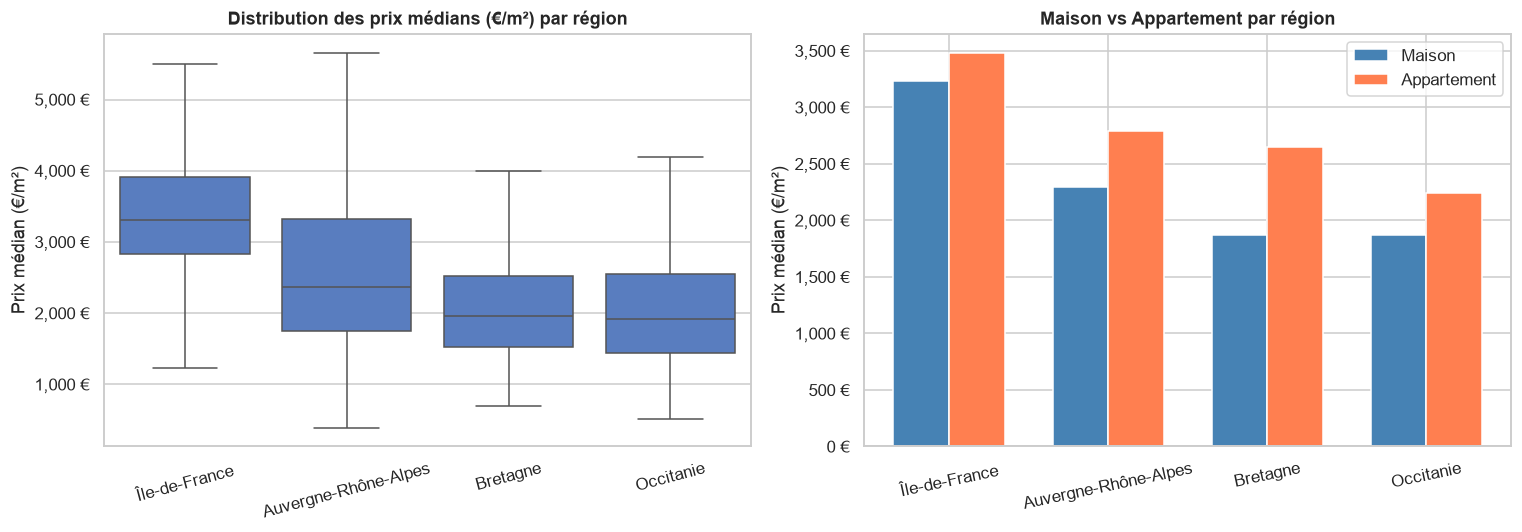

In [4]:
ordre_regions = (df_b1.groupby('region_label')['prix_m2_median']
                 .median().sort_values(ascending=False).index.tolist())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# distribution complète par région
sns.boxplot(data=df_b1, x='region_label', y='prix_m2_median',
            order=ordre_regions, ax=axes[0], showfliers=False)
axes[0].set_title('Distribution des prix médians (€/m²) par région', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Prix médian (€/m²)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,} €'))
axes[0].tick_params(axis='x', rotation=15)

# maison vs appartement par région
comp_type = (df_b1.groupby(['region_label', 'type_bien'])['prix_m2_median']
             .median().unstack().reindex(ordre_regions))
x = np.arange(len(comp_type))
width = 0.35
if 'Maison' in comp_type.columns:
    axes[1].bar(x - width/2, comp_type['Maison'], width, label='Maison', color='steelblue')
if 'Appartement' in comp_type.columns:
    axes[1].bar(x + width/2, comp_type['Appartement'], width, label='Appartement', color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(comp_type.index, rotation=12)
axes[1].set_ylabel('Prix médian (€/m²)')
axes[1].set_title('Maison vs Appartement par région', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,} €'))
axes[1].legend()

plt.tight_layout()
plt.show()

In [5]:
# top / flop communes via B1_comparaison_prix.sql (IDF, Maison)
df_b1_detail = run_sql('B1_comparaison_prix.sql')
print('=== Top 10 communes les plus chères (IDF, Maison) ===')
print(df_b1_detail.head(10).to_string(index=False))
print('\n=== 10 communes les moins chères (IDF, Maison) ===')
print(df_b1_detail.tail(10).to_string(index=False))

=== Top 10 communes les plus chères (IDF, Maison) ===
code_commune departement region type_bien  nb_ventes_total  prix_m2_median  prix_m2_moyen  prix_m2_min  prix_m2_max
       92051          92    idf    Maison            100.0         16563.0        16104.0      14354.0      17391.0
       77306          77    idf    Maison             26.0         15306.0        13627.0      15306.0      15306.0
       75056          75    idf    Maison            693.0         13777.0        14312.0      12455.0      14931.0
       92012          92    idf    Maison            167.0         13069.0        13976.0      12328.0      14413.0
       94018          94    idf    Maison             32.0         11670.0        11286.0      11670.0      11670.0
       94067          94    idf    Maison             40.0         11351.0        11860.0      11351.0      11351.0
       92024          92    idf    Maison             43.0         11268.0        10990.0      10955.0      11581.0
       94080      

---
## B2 — Score d'attractivité pour l'implantation d'agences

Le score est calculé dans le pipeline Gold (`src/gold/indicateurs.py`) à partir de 3 composantes, chacune normalisée en rang percentile (0–100) **au sein de la région** :

| Composante | Poids | Ce qu'elle mesure |
|------------|-------|-------------------|
| `score_dynamique` | 40 % | Variation de prix m² entre 2022-2023 et 2024-2025 — marchés en hausse = score élevé |
| `score_activite` | 30 % | Nombre de ventes 2024-2025 — communes les plus actives = score élevé |
| `score_equipements` | 30 % | Densité moyenne d'équipements (écoles, santé, commerces, transport) pour 1 000 habitants |

**score_attractivite = 0.40 × score_dynamique + 0.30 × score_activite + 0.30 × score_equipements**

Seules les communes *éligibles* ont un score : population > 0, ≥ 10 ventes récentes, dynamique de prix calculable.

In [6]:
# top 10 par région — on exécute le sql pour chaque région
resultats_b2 = {}
for region_code, region_label in LABELS_REGION.items():
    sql = (SQL_DIR / 'B2_classement_agences.sql').read_text(encoding='utf-8')
    sql_modif = sql.replace("'idf'", f"'{region_code}'")
    with engine.connect() as conn:
        df = pd.read_sql(text(sql_modif), conn)
    df['region_label'] = region_label
    resultats_b2[region_label] = df
    print(f"{region_label} : {len(df)} communes retournées")

df_b2 = pd.concat(resultats_b2.values(), ignore_index=True)
df_b2.head()

Île-de-France : 10 communes retournées


Auvergne-Rhône-Alpes : 10 communes retournées


Bretagne : 10 communes retournées


Occitanie : 10 communes retournées


,code_commune,departement,region,score_attractivite,score_dynamique,score_activite,score_equipements,dynamique_prix_pct,nb_ventes_2024_2025,nb_poi_osm,nb_arrets_transport,rang_dans_la_region,region_label
0,77186,77,idf,85.0,78.00,88.37,91.11,-2.36,466,325,40,1,Île-de-France
1,92062,92,idf,82.2,74.95,96.95,77.00,-3.18,992,619,59,2,Île-de-France
2,94067,94,idf,81.7,95.58,91.32,53.50,8.47,564,187,12,3,Île-de-France
3,77449,77,idf,81.1,80.74,74.53,88.08,-1.38,211,233,23,4,Île-de-France
4,78310,78,idf,81.0,92.32,60.11,86.87,4.07,93,89,10,5,Île-de-France


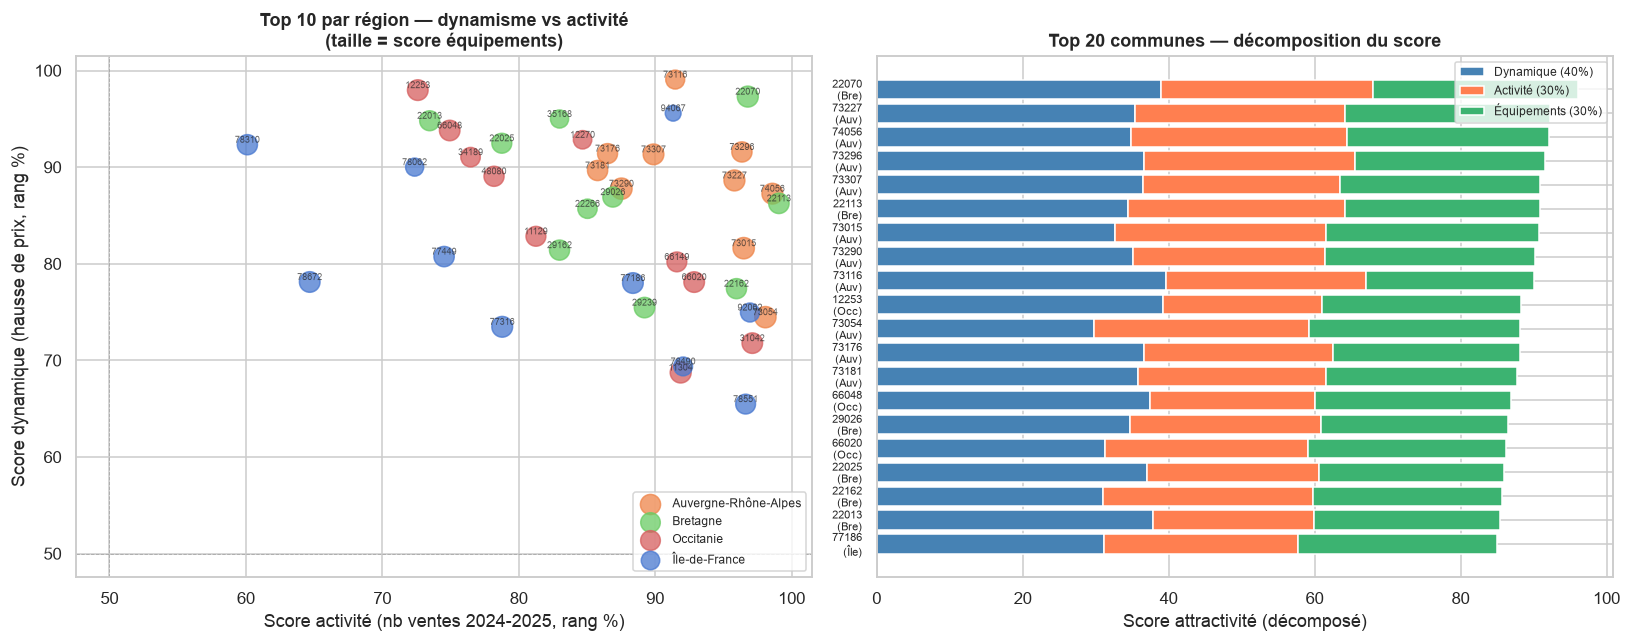

In [7]:
# scatter : dynamisme vs activité, taille = équipements — on voit ce qui drive le score
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

palette_region = dict(zip(LABELS_REGION.values(), sns.color_palette('muted', 4)))

for region_label, grp in df_b2.groupby('region_label'):
    axes[0].scatter(
        grp['score_activite'], grp['score_dynamique'],
        s=grp['score_equipements'] * 2,
        alpha=0.75, label=region_label,
        color=palette_region.get(region_label)
    )
    for _, row in grp.iterrows():
        axes[0].annotate(row['code_commune'],
                         (row['score_activite'], row['score_dynamique']),
                         fontsize=6, alpha=0.7, ha='center', va='bottom')

axes[0].set_xlabel('Score activité (nb ventes 2024-2025, rang %)')
axes[0].set_ylabel('Score dynamique (hausse de prix, rang %)')
axes[0].set_title('Top 10 par région — dynamisme vs activité\n(taille = score équipements)', fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].axhline(50, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)
axes[0].axvline(50, color='gray', linewidth=0.6, linestyle='--', alpha=0.5)

# décomposition du score en barres empilées pour le top 5 global
top5_global = df_b2.nlargest(20, 'score_attractivite').copy()
top5_global = top5_global.sort_values('score_attractivite', ascending=True)
top5_global['label'] = top5_global['code_commune'] + '\n(' + top5_global['region_label'].str[:3] + ')'

contrib_dynamique = top5_global['score_dynamique'] * 0.40
contrib_activite  = top5_global['score_activite']  * 0.30
contrib_equip     = top5_global['score_equipements'] * 0.30

y = np.arange(len(top5_global))
axes[1].barh(y, contrib_dynamique, label='Dynamique (40%)', color='steelblue')
axes[1].barh(y, contrib_activite,  left=contrib_dynamique, label='Activité (30%)', color='coral')
axes[1].barh(y, contrib_equip, left=contrib_dynamique + contrib_activite, label='Équipements (30%)', color='mediumseagreen')
axes[1].set_yticks(y)
axes[1].set_yticklabels(top5_global['label'], fontsize=7)
axes[1].set_xlabel('Score attractivité (décomposé)')
axes[1].set_title('Top 20 communes — décomposition du score', fontweight='bold')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [8]:
# stats résumées par région pour les communes éligibles
sql_score = """
SELECT region, score_attractivite, score_dynamique, score_activite, score_equipements,
       nb_ventes_2024_2025, dynamique_prix_pct
FROM "G_communes"
WHERE score_eligible = TRUE AND score_attractivite IS NOT NULL
"""
with engine.connect() as conn:
    df_score = pd.read_sql(text(sql_score), conn)

df_score['region_label'] = df_score['region'].map(LABELS_REGION)

print(f"Communes éligibles au scoring : {len(df_score):,}")
print(df_score.groupby('region_label')[['score_attractivite','score_dynamique','score_activite','score_equipements']].describe().round(1).to_string())

Communes éligibles au scoring : 6,136
                     score_attractivite                                          score_dynamique                                           score_activite                                           score_equipements                                          
                                  count  mean   std  min   25%   50%   75%   max           count  mean   std  min   25%   50%   75%    max          count  mean   std  min   25%   50%   75%    max             count  mean   std   min   25%   50%   75%   max
region_label                                                                                                                                                                                                                                                   
Auvergne-Rhône-Alpes             2338.0  50.0  17.4  4.7  38.7  51.5  63.2  92.2          2338.0  50.0  28.9  0.1  25.0  50.0  75.0   99.8         2338.0  50.0  28.9  1.4  24.9  50.7  74.9  100.

---
## B3 — Profil socio-démographique des communes

Pour chaque commune on dispose d'indicateurs INSEE : revenu médian, taux de chômage, part des diplômés du supérieur, part des 65 ans et plus, taux de vacance logement.

L'objectif est d'identifier le **profil type** des communes à fort potentiel immobilier pour aider l'agence à cibler ses prospects.

In [9]:
# toutes les régions — on enlève le filtre region du SQL
sql_b3 = """
SELECT
    c.code_commune, c.departement, c.region, c.population,
    c.revenu_median, c.taux_chomage, c.taux_vacance,
    c.part_diplome_superieur, c.part_moins_15, c.part_65_plus,
    COALESCE(c.prix_m2_median_maison_2024_2025, c.prix_m2_median_appartement_2024_2025) AS prix_m2_recent
FROM "G_communes" AS c
WHERE c.population > 0 AND c.revenu_median IS NOT NULL
ORDER BY c.revenu_median DESC
"""
with engine.connect() as conn:
    df_b3 = pd.read_sql(text(sql_b3), conn)

df_b3['region_label'] = df_b3['region'].map(LABELS_REGION)
print(f"{len(df_b3):,} communes chargées")

# profil des 10 communes les plus riches vs 10 les plus pauvres
cols_profil = ['code_commune', 'departement', 'revenu_median', 'taux_chomage',
               'part_diplome_superieur', 'part_65_plus', 'taux_vacance', 'prix_m2_recent']

print("\n=== 10 communes avec le revenu médian le plus élevé ===")
print(df_b3[cols_profil].head(10).to_string(index=False))

print("\n=== 10 communes avec le revenu médian le plus faible ===")
print(df_b3[cols_profil].tail(10).to_string(index=False))

9,658 communes chargées

=== 10 communes avec le revenu médian le plus élevé ===
code_commune departement  revenu_median  taux_chomage  part_diplome_superieur  part_65_plus  taux_vacance  prix_m2_recent
       74044          74        62730.0          6.44                   57.11         15.63          7.92          6755.5
       01180          01        60900.0          7.77                   61.33         18.19          8.24          5372.0
       74016          74        59760.0          7.08                   53.44         14.44          5.62          6032.5
       92051          92        56030.0          8.13                   73.32         22.63          8.08         16333.0
       74009          74        55950.0          7.42                   51.65          9.95          6.90             NaN
       74199          74        55540.0         11.14                   59.68         28.19          1.12          5519.5
       01153          01        54700.0          7.54            

=== Profil moyen par segment de communes ===
               nb_communes  revenu_median_moy  taux_chomage_moy  diplome_sup_moy  part_65_moy  taux_vacance_moy  prix_m2_moy
profil                                                                                                                      
Revenu faible         3221            22764.0              11.3             25.8         28.6              10.0       1720.4
Revenu moyen          3222            25931.2               8.1             29.7         23.6               7.7       2136.3
Revenu élevé          3215            31109.1               6.8             40.1         19.7               6.0       3337.8


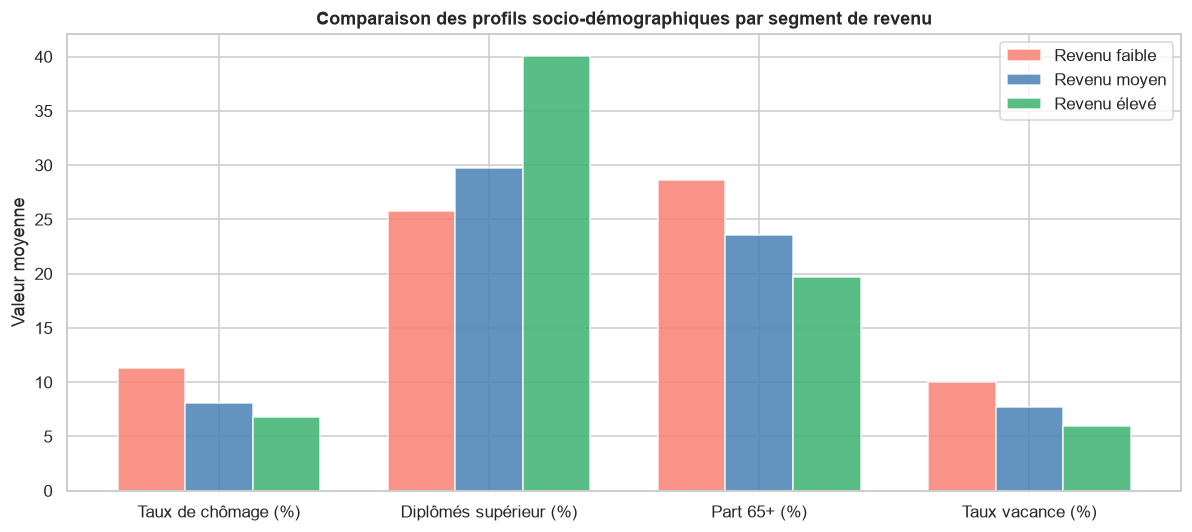

In [10]:
# on segmente les communes en 3 profils selon le revenu médian
df_b3['profil'] = pd.qcut(df_b3['revenu_median'], q=3,
                           labels=['Revenu faible', 'Revenu moyen', 'Revenu élevé'])

# profil moyen de chaque segment sur les indicateurs clés
profil_segments = df_b3.groupby('profil', observed=True).agg(
    nb_communes=('code_commune', 'count'),
    revenu_median_moy=('revenu_median', 'mean'),
    taux_chomage_moy=('taux_chomage', 'mean'),
    diplome_sup_moy=('part_diplome_superieur', 'mean'),
    part_65_moy=('part_65_plus', 'mean'),
    taux_vacance_moy=('taux_vacance', 'mean'),
    prix_m2_moy=('prix_m2_recent', 'mean'),
).round(1)

print("=== Profil moyen par segment de communes ===")
print(profil_segments.to_string())

# graphe comparatif des 3 profils sur 4 indicateurs
indicateurs = {
    'taux_chomage_moy':   'Taux de chômage (%)',
    'diplome_sup_moy':    'Diplômés supérieur (%)',
    'part_65_moy':        'Part 65+ (%)',
    'taux_vacance_moy':   'Taux vacance (%)',
}

x = np.arange(len(indicateurs))
width = 0.25
couleurs = ['salmon', 'steelblue', 'mediumseagreen']
labels_seg = profil_segments.index.tolist()

fig, ax = plt.subplots(figsize=(11, 5))
for i, (label, couleur) in enumerate(zip(labels_seg, couleurs)):
    vals = [profil_segments.loc[label, col] for col in indicateurs]
    ax.bar(x + i * width, vals, width, label=label, color=couleur, alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(indicateurs.values())
ax.set_ylabel('Valeur moyenne')
ax.set_title('Comparaison des profils socio-démographiques par segment de revenu', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

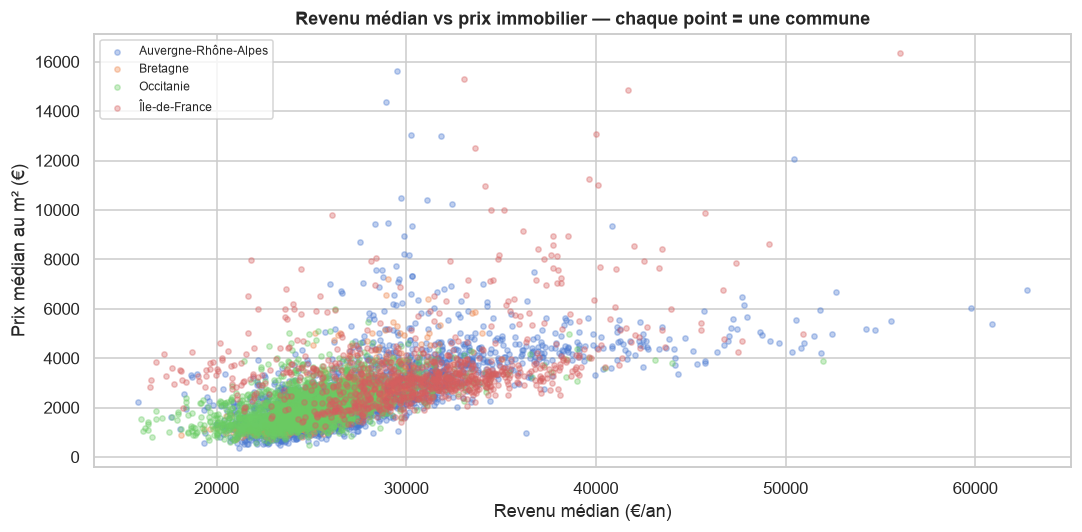

In [11]:
# revenu vs prix — lien direct visible par commune
df_sc = df_b3.dropna(subset=['prix_m2_recent'])

fig, ax = plt.subplots(figsize=(10, 5))
for region, grp in df_sc.groupby('region_label'):
    ax.scatter(grp['revenu_median'], grp['prix_m2_recent'],
               alpha=0.35, s=12, label=region)

ax.set_xlabel('Revenu médian (€/an)')
ax.set_ylabel('Prix médian au m² (€)')
ax.set_title('Revenu médian vs prix immobilier — chaque point = une commune', fontweight='bold')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## B4 — Tendance des prix 2021–2025

On exécute `B4_tendance_marche.sql` pour suivre l'évolution annuelle des prix au m² par commune. On visualise ensuite les tendances agrégées par région.

In [12]:
# tendance globale par région (toutes communes, toutes années)
sql_b4_global = """
SELECT
    m.annee,
    c.region,
    m.type_bien,
    COUNT(DISTINCT m.code_commune) AS nb_communes,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY m.prix_m2_median)::numeric, 0) AS prix_m2_median,
    ROUND(AVG(m.variation_annuelle_pct)::numeric, 1) AS variation_moy_pct
FROM "G_marche_commune_annee_type" AS m
JOIN "G_communes" AS c ON c.code_commune = m.code_commune
WHERE m.prix_m2_median IS NOT NULL
GROUP BY m.annee, c.region, m.type_bien
ORDER BY c.region, m.type_bien, m.annee
"""

with engine.connect() as conn:
    df_b4 = pd.read_sql(text(sql_b4_global), conn)

df_b4['region_label'] = df_b4['region'].map(LABELS_REGION)
print(f"{len(df_b4)} lignes (région × type_bien × année)")
df_b4.head(8)

40 lignes (région × type_bien × année)


,annee,region,type_bien,nb_communes,prix_m2_median,variation_moy_pct,region_label
0,2021,ara,Appartement,584,2667.0,NaN,Auvergne-Rhône-Alpes
1,2022,ara,Appartement,582,2831.0,9.3,Auvergne-Rhône-Alpes
2,2023,ara,Appartement,535,2970.0,3.8,Auvergne-Rhône-Alpes
3,2024,ara,Appartement,500,2830.0,-1.6,Auvergne-Rhône-Alpes
4,2025,ara,Appartement,528,3016.0,3.8,Auvergne-Rhône-Alpes
5,2021,ara,Maison,1940,2201.0,NaN,Auvergne-Rhône-Alpes
6,2022,ara,Maison,1865,2446.0,11.5,Auvergne-Rhône-Alpes
7,2023,ara,Maison,1469,2468.0,1.0,Auvergne-Rhône-Alpes


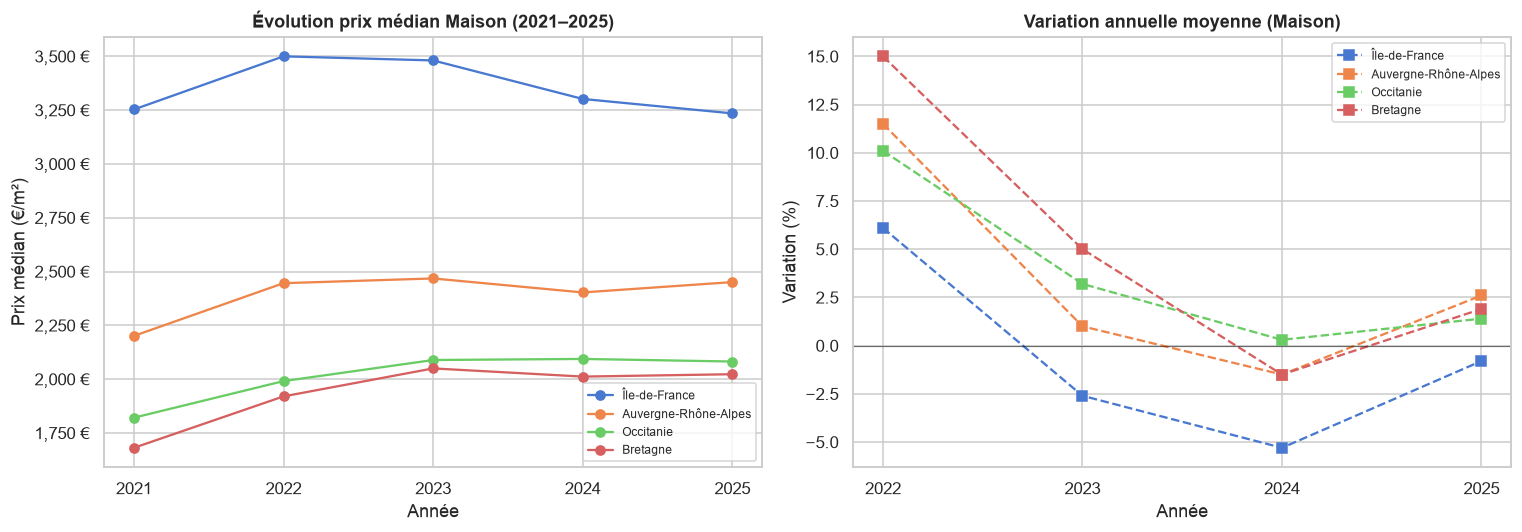

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for region in ORDRE_REGIONS:
    sub = df_b4[(df_b4['region_label'] == region) & (df_b4['type_bien'] == 'Maison')]
    if not sub.empty:
        axes[0].plot(sub['annee'], sub['prix_m2_median'], marker='o', label=region)

axes[0].set_title('Évolution prix médian Maison (2021–2025)', fontweight='bold')
axes[0].set_xlabel('Année')
axes[0].set_ylabel('Prix médian (€/m²)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,} €'))
axes[0].legend(fontsize=8)
axes[0].set_xticks([2021, 2022, 2023, 2024, 2025])

df_var = df_b4.dropna(subset=['variation_moy_pct'])
for region in ORDRE_REGIONS:
    sub = df_var[(df_var['region_label'] == region) & (df_var['type_bien'] == 'Maison')]
    if not sub.empty:
        axes[1].plot(sub['annee'], sub['variation_moy_pct'], marker='s',
                     linestyle='--', label=region)

axes[1].axhline(0, color='black', linewidth=0.8, alpha=0.5)
axes[1].set_title('Variation annuelle moyenne (Maison)', fontweight='bold')
axes[1].set_xlabel('Année')
axes[1].set_ylabel('Variation (%)')
axes[1].legend(fontsize=8)
axes[1].set_xticks([2022, 2023, 2024, 2025])

plt.tight_layout()
plt.show()

=== Tendance Paris (75056) — Appartement ===
code_commune   type_bien  annee  nb_ventes  prix_m2_median  prix_m2_moyen  variation_annuelle_pct tendance_annuelle  variation_2021_2025_pct tendance_2021_2025
       75056 Appartement   2021      31113         10833.0       10942.40                     NaN    non_concluante                    -10.5             baisse
       75056 Appartement   2022      33862         10714.0       10896.20                   -1.10            stable                    -10.5             baisse
       75056 Appartement   2023      27464         10135.0       10400.30                   -5.40            baisse                    -10.5             baisse
       75056 Appartement   2024      25017          9564.0        9861.75                   -5.63            baisse                    -10.5             baisse
       75056 Appartement   2025      28889          9695.0       10020.08                    1.37            stable                    -10.5             ba

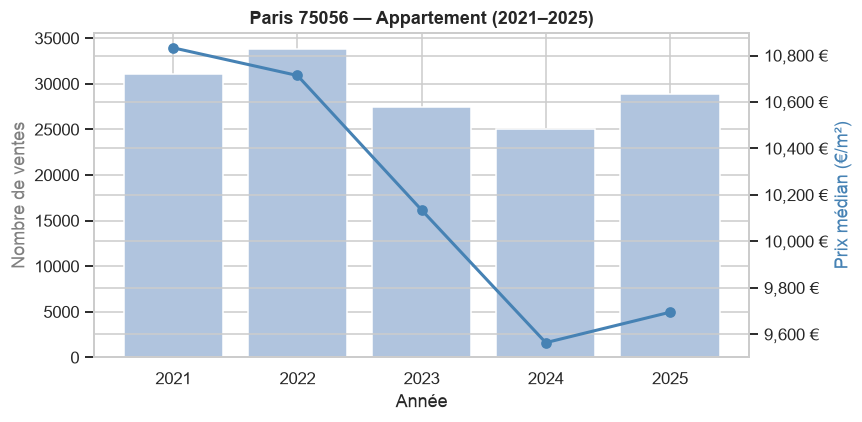

In [14]:
# zoom sur une commune via B4_tendance_marche.sql (Paris 75056, Appartement)
df_b4_paris = run_sql('B4_tendance_marche.sql')
print('=== Tendance Paris (75056) — Appartement ===')
print(df_b4_paris.to_string(index=False))

if not df_b4_paris.empty and df_b4_paris['prix_m2_median'].notna().any():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(df_b4_paris['annee'], df_b4_paris['nb_ventes'], color='lightsteelblue', label='nb ventes')
    ax2 = ax.twinx()
    ax2.plot(df_b4_paris['annee'], df_b4_paris['prix_m2_median'], color='steelblue',
             marker='o', linewidth=2, label='prix médian')
    ax.set_xlabel('Année')
    ax.set_ylabel('Nombre de ventes', color='gray')
    ax2.set_ylabel('Prix médian (€/m²)', color='steelblue')
    ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,} €'))
    ax.set_title('Paris 75056 — Appartement (2021–2025)', fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## B5 — Zones sous-valorisées et bien équipées

On exécute `B5_zones_prix_bas_equipees.sql` sur `G_communes`. Les communes retournées ont un prix inférieur à 90% du médian régional, un score équipements ≥ 60 et un revenu médian au-dessus de la médiane régionale.

In [15]:
resultats_b5 = {}
for region_code, region_label in LABELS_REGION.items():
    sql = (SQL_DIR / 'B5_zones_prix_bas_equipees.sql').read_text(encoding='utf-8')
    sql_modif = sql.replace("'occitanie'", f"'{region_code}'")
    with engine.connect() as conn:
        df = pd.read_sql(text(sql_modif), conn)
    df['region_label'] = region_label
    resultats_b5[region_label] = df
    print(f"{region_label} : {len(df)} zones d'opportunité")

df_b5 = pd.concat(resultats_b5.values(), ignore_index=True)
print(f"\nTotal : {len(df_b5)} communes identifiées")
df_b5.head()

Île-de-France : 8 zones d'opportunité
Auvergne-Rhône-Alpes : 10 zones d'opportunité


Bretagne : 6 zones d'opportunité


Occitanie : 10 zones d'opportunité

Total : 34 communes identifiées


,code_commune,departement,region,type_bien,nb_ventes_2024_2025,prix_m2_median,prix_m2_median_regional,ecart_prix_region_pct,score_equipements,score_attractivite,revenu_median,revenu_median_regional,communes_reference,region_label
0,78296,78,idf,Maison,11,2395.0,3171.75,-24.5,71.89,29.1,32990.0,30270.0,948,Île-de-France
1,77477,77,idf,Maison,19,2400.0,3171.75,-24.3,79.18,32.4,30680.0,30270.0,948,Île-de-France
2,77264,77,idf,Maison,38,2432.0,3171.75,-23.3,60.53,36.4,30280.0,30270.0,948,Île-de-France
3,78564,78,idf,Maison,12,2470.5,3171.75,-22.1,69.43,51.7,32060.0,30270.0,948,Île-de-France
4,77082,77,idf,Maison,16,2577.5,3171.75,-18.7,75.76,50.6,30730.0,30270.0,948,Île-de-France


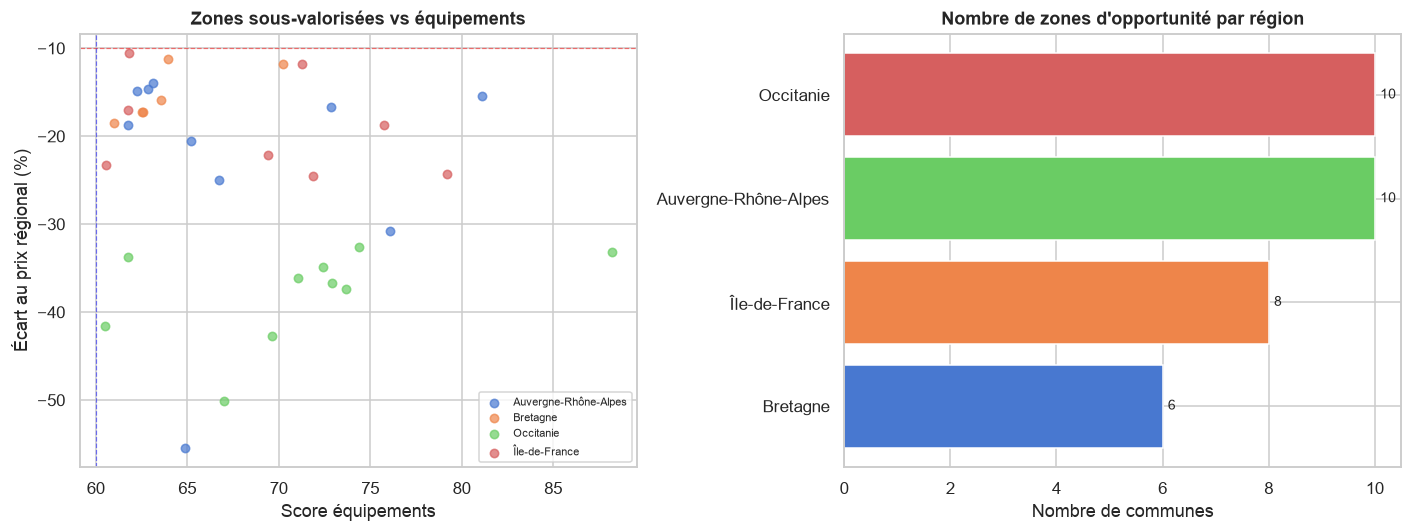


=== Top 5 par région (écart le plus bas) ===
code_commune departement         region_label  prix_m2_median  prix_m2_median_regional  ecart_prix_region_pct  score_equipements  revenu_median
       03195          03 Auvergne-Rhône-Alpes          1039.5                  2332.00                  -55.4              64.89        27410.0
       03286          03 Auvergne-Rhône-Alpes          1614.5                  2332.00                  -30.8              76.06        27540.0
       42267          42 Auvergne-Rhône-Alpes          1750.0                  2332.00                  -25.0              66.71        27580.0
       42120          42 Auvergne-Rhône-Alpes          1855.0                  2332.00                  -20.5              65.23        27460.0
       42182          42 Auvergne-Rhône-Alpes          1895.0                  2332.00                  -18.7              61.74        27370.0
       29086          29             Bretagne          1575.5                  1932.75    

In [16]:
if len(df_b5) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # scatter prix vs score équipements
    for region, grp in df_b5.groupby('region_label'):
        axes[0].scatter(grp['score_equipements'], grp['ecart_prix_region_pct'],
                        s=30, alpha=0.7, label=region)
    axes[0].axhline(-10, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
    axes[0].axvline(60, color='blue', linestyle='--', linewidth=0.8, alpha=0.5)
    axes[0].set_xlabel('Score équipements')
    axes[0].set_ylabel('Écart au prix régional (%)')
    axes[0].set_title('Zones sous-valorisées vs équipements', fontweight='bold')
    axes[0].legend(fontsize=7)

    # nb par région
    nb_par_region = df_b5.groupby('region_label').size().sort_values(ascending=True)
    axes[1].barh(nb_par_region.index, nb_par_region.values,
                 color=sns.color_palette('muted', len(nb_par_region)))
    axes[1].set_xlabel('Nombre de communes')
    axes[1].set_title("Nombre de zones d'opportunité par région", fontweight='bold')
    for i, val in enumerate(nb_par_region.values):
        axes[1].text(val + 0.1, i, str(val), va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    print('\n=== Top 5 par région (écart le plus bas) ===')
    cols_aff = ['code_commune', 'departement', 'region_label', 'prix_m2_median',
                'prix_m2_median_regional', 'ecart_prix_region_pct', 'score_equipements', 'revenu_median']
    top5 = (df_b5.groupby('region_label', group_keys=False)
            .apply(lambda g: g.nsmallest(5, 'ecart_prix_region_pct'))
            .reset_index(drop=True))
    print(top5[[c for c in cols_aff if c in top5.columns]].to_string(index=False))

In [17]:
# export CSV
if len(df_b5) > 0:
    export_path = ROOT / 'gold' / 'B5_zones_opportunite.csv'
    df_b5.sort_values(['region_label', 'ecart_prix_region_pct']).to_csv(export_path, index=False, encoding='utf-8')
    print(f"Export : {len(df_b5)} communes → {export_path}")

engine.dispose()
print('Connexion PostgreSQL fermée.')

Export : 34 communes → /Users/rayanhachemi/Desktop/TP DL/gold/B5_zones_opportunite.csv
Connexion PostgreSQL fermée.


---
## Récapitulatif

| Besoin | Requête SQL | Table(s) Gold | Résultat clé |
|--------|------------|---------------|--------------|
| B1 | `B1_comparaison_prix.sql` | G_marche_commune_annee_type + G_communes | Prix médian IDF ≫ autres régions |
| B2 | `B2_classement_agences.sql` | G_communes | Top 10 par région selon score_attractivite |
| B3 | `B3_profil_sociodemographique.sql` | G_communes | Lien fort revenu ↔ prix ; IDF : diplôme élevé |
| B4 | `B4_tendance_marche.sql` | G_marche_commune_annee_type + G_communes | Hausse 2021–2023, ralentissement 2024–2025 |
| B5 | `B5_zones_prix_bas_equipees.sql` | G_communes | Zones d'opportunité en périphérie et ARA |